<a href="https://colab.research.google.com/github/vandau16/THXDMHTTNT/blob/main/BaiTap_HoiQuy_DoQuangDat_23104900095_CLEAN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## BÀI 1. PHÂN TÍCH KHÁM PHÁ DỮ LIỆU DIABETES

Chọn ba đặc trưng `bmi`, `bp`, `s5`; xem thống kê, phân phối, ngoại lệ IQR, tương quan và scatter plot với target.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes
from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from IPython.display import display

diabetes = load_diabetes(as_frame=True)
X_diabetes = diabetes.data.copy()
y_diabetes = diabetes.target.copy()
df_diabetes = X_diabetes.copy()
df_diabetes['target'] = y_diabetes
print('Kích thước dữ liệu:', df_diabetes.shape)
print('Giá trị thiếu:', df_diabetes.isna().sum().sum())
print('Dòng trùng lặp:', df_diabetes.duplicated().sum())
display(df_diabetes.head())


Kích thước dữ liệu: (442, 11)
Giá trị thiếu: 0
Dòng trùng lặp: 0


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0



bmi: số mẫu=442, trung bình=-0.0000, độ lệch chuẩn=0.0476, min=-0.0903, trung vị=-0.0073, max=0.1706

bp: số mẫu=442, trung bình=-0.0000, độ lệch chuẩn=0.0476, min=-0.1124, trung vị=-0.0057, max=0.1320

s5: số mẫu=442, trung bình=0.0000, độ lệch chuẩn=0.0476, min=-0.1261, trung vị=-0.0019, max=0.1336


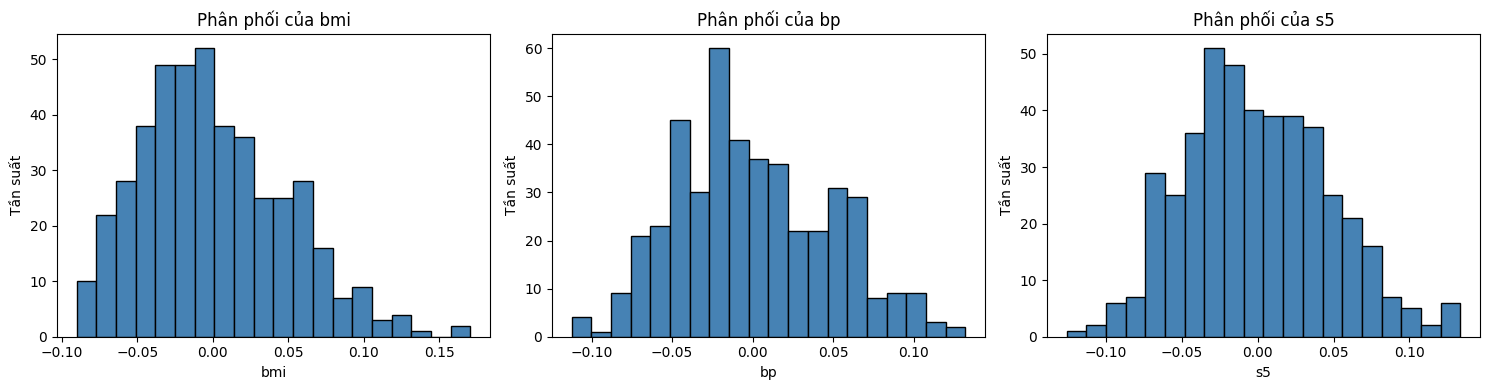

In [2]:
features_3 = ['bmi', 'bp', 's5']

# Thống kê mô tả và histogram
for col in features_3:
    values = df_diabetes[col]
    print(f'\n{col}: số mẫu={values.count()}, trung bình={values.mean():.4f}, độ lệch chuẩn={values.std():.4f}, min={values.min():.4f}, trung vị={values.median():.4f}, max={values.max():.4f}')

plt.figure(figsize=(15, 4))
for i, col in enumerate(features_3, 1):
    plt.subplot(1, 3, i)
    plt.hist(df_diabetes[col], bins=20, edgecolor='black', color='steelblue')
    plt.title(f'Phân phối của {col}')
    plt.xlabel(col)
    plt.ylabel('Tần suất')
plt.tight_layout()
plt.show()


,Biến,Q1,Q3,IQR,Ngưỡng dưới,Ngưỡng trên,Số ngoại lệ
0,bmi,-0.0342,0.0312,0.0655,-0.1324,0.1295,3
1,bp,-0.0367,0.0356,0.0723,-0.1451,0.1441,0
2,s5,-0.0332,0.0324,0.0657,-0.1318,0.1309,4


/tmp/ipykernel_1188/1323424673.py:13: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([df_diabetes[col] for col in features_3], labels=features_3)


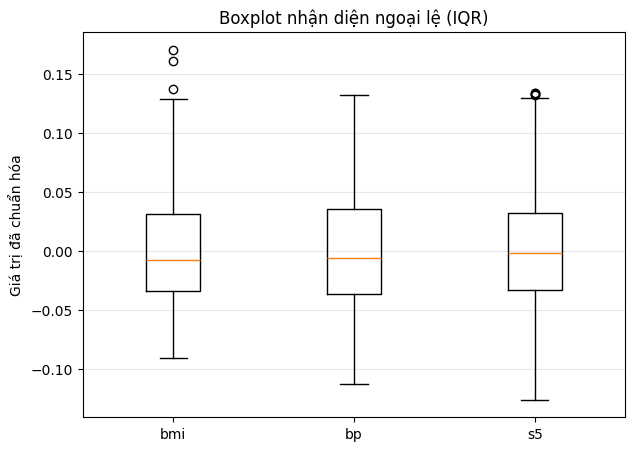

In [3]:
# Ngoại lệ theo quy tắc IQR và Boxplot
outlier_rows = []
for col in features_3:
    Q1 = df_diabetes[col].quantile(0.25)
    Q3 = df_diabetes[col].quantile(0.75)
    IQR = Q3 - Q1
    lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
    count = ((df_diabetes[col] < lower) | (df_diabetes[col] > upper)).sum()
    outlier_rows.append([col, Q1, Q3, IQR, lower, upper, count])
display(pd.DataFrame(outlier_rows, columns=['Biến','Q1','Q3','IQR','Ngưỡng dưới','Ngưỡng trên','Số ngoại lệ']).round(4))

plt.figure(figsize=(7, 5))
plt.boxplot([df_diabetes[col] for col in features_3], labels=features_3)
plt.title('Boxplot nhận diện ngoại lệ (IQR)')
plt.ylabel('Giá trị đã chuẩn hóa')
plt.grid(axis='y', alpha=0.3)
plt.show()


Tương quan bmi với target: r = 0.5865
Tương quan bp với target: r = 0.4415
Tương quan s5 với target: r = 0.5659


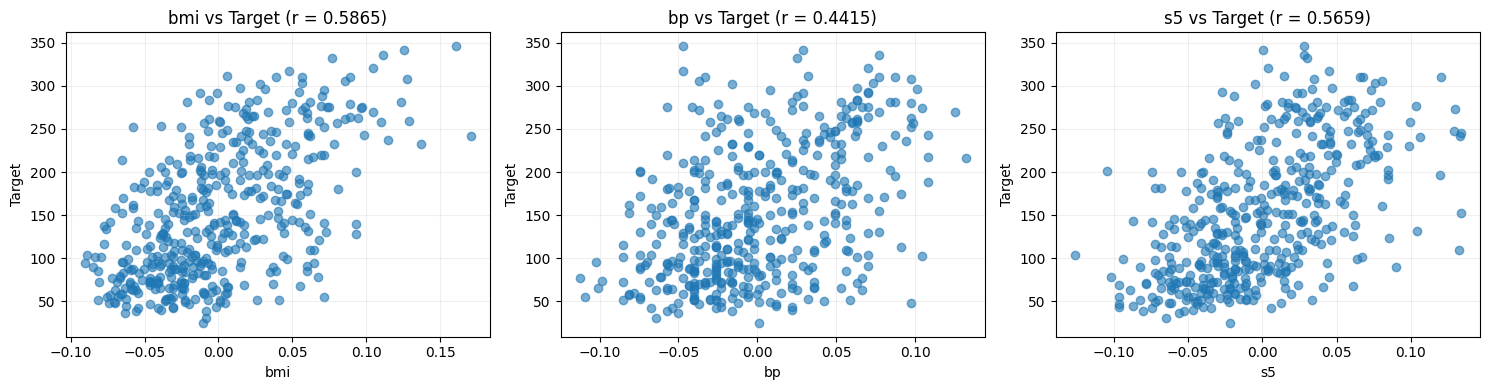

In [4]:
# Tương quan Pearson và scatter plot
corr_diabetes = df_diabetes[features_3 + ['target']].corr()
plt.figure(figsize=(15, 4))
for i, col in enumerate(features_3, 1):
    r = corr_diabetes.loc[col, 'target']
    print(f'Tương quan {col} với target: r = {r:.4f}')
    plt.subplot(1, 3, i)
    plt.scatter(df_diabetes[col], df_diabetes['target'], alpha=0.6)
    plt.title(f'{col} vs Target (r = {r:.4f})')
    plt.xlabel(col)
    plt.ylabel('Target')
    plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


## BÀI 2. LINEAR REGRESSION VỚI CÁC NHÓM ĐẶC TRƯNG

So sánh `bmi`, `bmi + bp`, Top 5 và toàn bộ 10 đặc trưng. Top 5 được chọn chỉ dựa trên tập Train để tránh rò rỉ dữ liệu.


In [5]:
X2_train, X2_test, y2_train, y2_test = train_test_split(X_diabetes, y_diabetes, test_size=0.2, random_state=42)
train_corr = X2_train.copy()
train_corr['target'] = y2_train
corr_top5 = train_corr.corr()['target'].drop('target')
top5_diabetes = corr_top5.abs().sort_values(ascending=False).head(5).index.tolist()
print('Top 5 đặc trưng:', top5_diabetes)
display(corr_top5.loc[top5_diabetes].to_frame('Pearson r').round(4))

groups = {'bmi':['bmi'], 'bmi + bp':['bmi','bp'], 'Top 5 features':top5_diabetes, 'All 10 features':list(X_diabetes.columns)}
results_b2 = []
predictions_b2 = {}
for group, cols in groups.items():
    model = LinearRegression()
    model.fit(X2_train[cols], y2_train)
    pred = model.predict(X2_test[cols])
    predictions_b2[group] = pred
    results_b2.append({'Bộ đặc trưng':group, 'Số đặc trưng':len(cols), 'MAE':mean_absolute_error(y2_test,pred), 'RMSE':np.sqrt(mean_squared_error(y2_test,pred)), 'R²':r2_score(y2_test,pred)})
results_b2_df = pd.DataFrame(results_b2)
display(results_b2_df.round(4))


Top 5 đặc trưng: ['bmi', 's5', 'bp', 's4', 's6']


,Pearson r
bmi,0.6048
s5,0.5522
bp,0.4448
s4,0.4251
s6,0.3904


,Bộ đặc trưng,Số đặc trưng,MAE,RMSE,R²
0,bmi,1,52.2600,63.7325,0.2334
1,bmi + bp,2,50.0441,61.1597,0.2940
2,Top 5 features,5,44.3288,53.8493,0.4527
3,All 10 features,10,42.7941,53.8534,0.4526


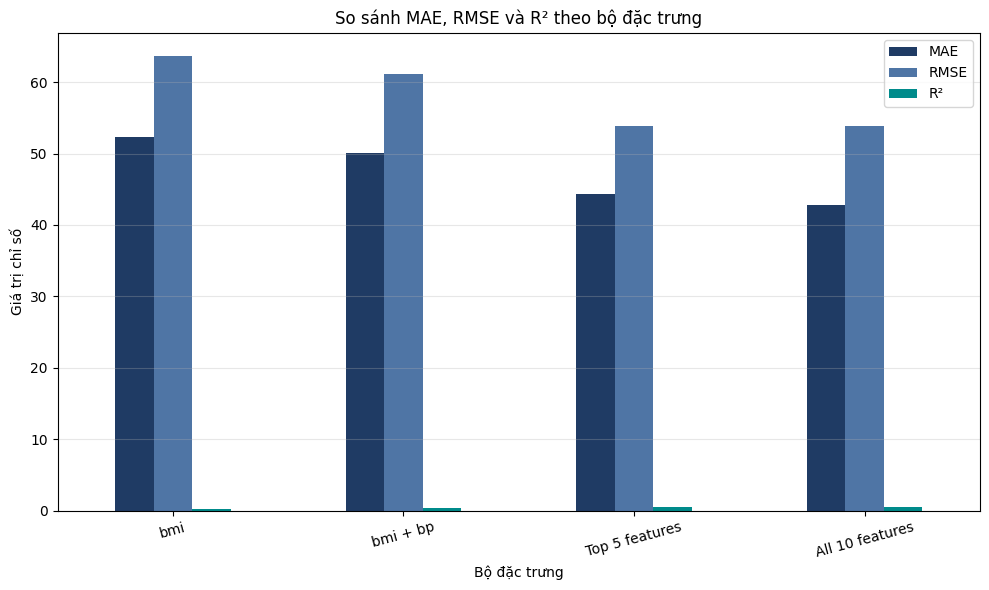

RMSE thấp nhất: Top 5 features 53.8493
MAE càng thấp càng tốt; RMSE càng thấp càng tốt; R² càng cao càng tốt.


In [6]:
# So sánh các chỉ số của Bài 2
results_b2_df.set_index('Bộ đặc trưng')[['MAE','RMSE','R²']].plot(kind='bar', figsize=(10,6), color=['#1f3b64','#4f75a5','#008b8b'])
plt.title('So sánh MAE, RMSE và R² theo bộ đặc trưng')
plt.ylabel('Giá trị chỉ số')
plt.xticks(rotation=15)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()
best_b2 = results_b2_df.loc[results_b2_df['RMSE'].idxmin()]
print('RMSE thấp nhất:', best_b2['Bộ đặc trưng'], round(best_b2['RMSE'],4))
print('MAE càng thấp càng tốt; RMSE càng thấp càng tốt; R² càng cao càng tốt.')


## BÀI 3. SO SÁNH THUẬT TOÁN HỒI QUY TRÊN DIABETES

Dùng toàn bộ 10 đặc trưng và cùng cách chia Train/Test (80/20, random_state=42).


In [7]:
models_b3 = {
    'Linear Regression': make_pipeline(StandardScaler(), LinearRegression()),
    'Ridge Regression': make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    'Decision Tree': DecisionTreeRegressor(max_depth=4, random_state=42),
    'SVR (RBF Kernel)': make_pipeline(StandardScaler(), SVR(kernel='rbf', C=100, epsilon=0.1)),
    'Gradient Boosting': GradientBoostingRegressor(n_estimators=100, learning_rate=0.05, max_depth=2, random_state=42)
}
results_b3 = []
predictions_b3 = {}
for name, model in models_b3.items():
    model.fit(X2_train, y2_train)
    pred = model.predict(X2_test)
    predictions_b3[name] = pred
    results_b3.append({'Thuật toán':name, 'MAE':mean_absolute_error(y2_test,pred), 'RMSE':np.sqrt(mean_squared_error(y2_test,pred)), 'R²':r2_score(y2_test,pred)})
results_b3_df = pd.DataFrame(results_b3).sort_values('R²', ascending=False).reset_index(drop=True)
display(results_b3_df.round(4))


,Thuật toán,MAE,RMSE,R²
0,SVR (RBF Kernel),39.4187,51.0641,0.5078
1,Gradient Boosting,42.5461,52.3725,0.4823
2,Ridge Regression,42.8120,53.7775,0.4541
3,Linear Regression,42.7941,53.8534,0.4526
4,Decision Tree,47.0454,59.7408,0.3264


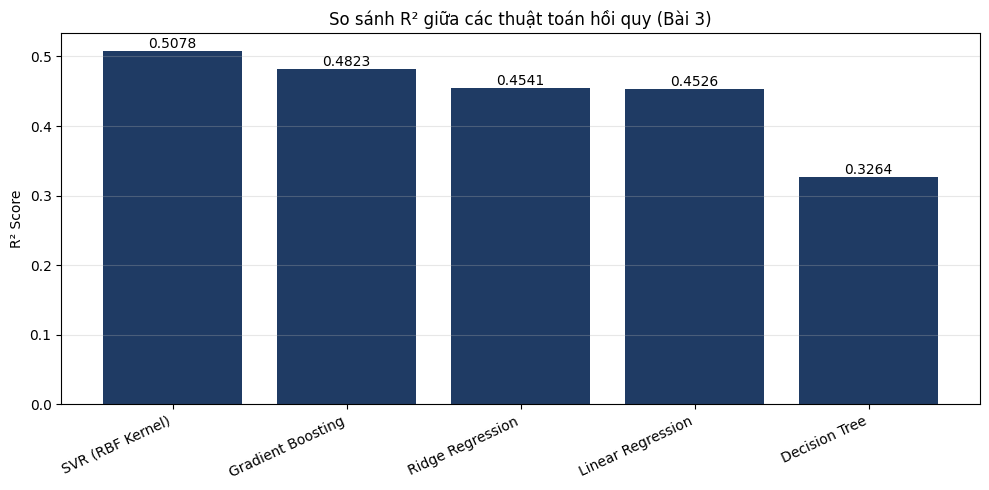

Mô hình tốt nhất theo R²: SVR (RBF Kernel)


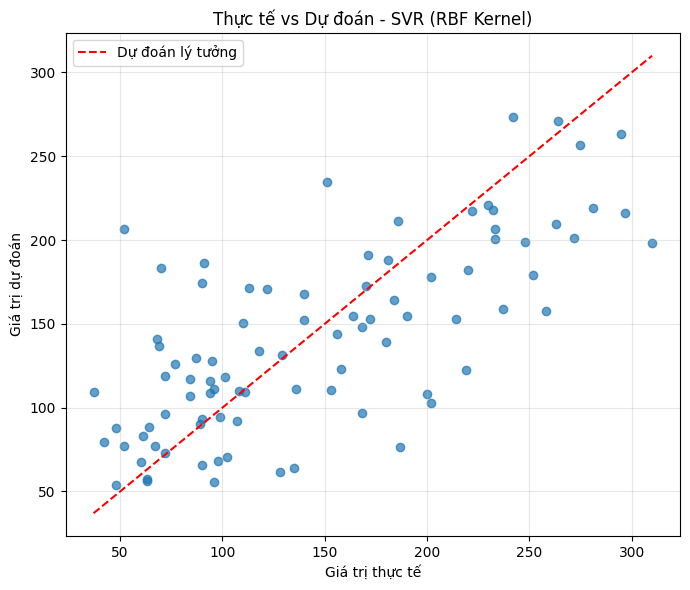

In [8]:
# So sánh R² và xem dự đoán của mô hình có R² tốt nhất
plt.figure(figsize=(10,5))
bars = plt.bar(results_b3_df['Thuật toán'], results_b3_df['R²'], color='#1f3b64')
plt.title('So sánh R² giữa các thuật toán hồi quy (Bài 3)')
plt.ylabel('R² Score')
plt.xticks(rotation=25, ha='right')
plt.grid(axis='y', alpha=0.3)
for bar, val in zip(bars, results_b3_df['R²']): plt.text(bar.get_x()+bar.get_width()/2, bar.get_height(), f'{val:.4f}', ha='center', va='bottom')
plt.tight_layout()
plt.show()
best_b3_name = results_b3_df.loc[0, 'Thuật toán']
best_b3_pred = predictions_b3[best_b3_name]
print('Mô hình tốt nhất theo R²:', best_b3_name)
plt.figure(figsize=(7,6))
plt.scatter(y2_test, best_b3_pred, alpha=0.7)
lo, hi = min(y2_test.min(), best_b3_pred.min()), max(y2_test.max(), best_b3_pred.max())
plt.plot([lo,hi],[lo,hi],'r--',label='Dự đoán lý tưởng')
plt.title(f'Thực tế vs Dự đoán - {best_b3_name}')
plt.xlabel('Giá trị thực tế'); plt.ylabel('Giá trị dự đoán'); plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()


## BÀI 4. PIPELINE HỒI QUY DỰ ĐOÁN GIÁ NHÀ KC HOUSE

Tải dữ liệu từ UCI; làm sạch và tạo đặc trưng; so sánh 6 mô hình trên All features và Top 10. Top 10 được chọn tương quan trên tập Train.


In [9]:
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer


In [10]:
# Đọc CSV KC House từ kho dữ liệu công khai trên GitHub.
data_url = 'https://raw.githubusercontent.com/halmonchaquayla/King-County-House-Prices/main/data/kc_house_data.csv'
house = pd.read_csv(data_url)

# Làm sạch dữ liệu và tạo các đặc trưng mới.
house = house.loc[house['price'] > 0].copy()
house['date'] = pd.to_datetime(house['date'], errors='coerce')
house['sale_year'] = house['date'].dt.year
house['sale_month'] = house['date'].dt.month
house['house_age'] = house['sale_year'] - house['yr_built']
house['renovated'] = (house['yr_renovated'] > 0).astype(int)
house['years_since_renovation'] = np.where(house['yr_renovated'] > 0, house['sale_year'] - house['yr_renovated'], house['house_age'])
house['living_lot_ratio'] = house['sqft_living'] / house['sqft_lot'].replace(0, np.nan)
house['bath_bed_ratio'] = house['bathrooms'] / house['bedrooms'].replace(0, np.nan)
y_house = house['price'].copy()
X_house = house.drop(columns=['price', 'date', 'id'], errors='ignore')
# Chuyển dữ liệu về số; các giá trị '?' sẽ thành NaN và được impute.
X_house = X_house.apply(pd.to_numeric, errors='coerce')
print('Kích thước sau tạo đặc trưng:', X_house.shape)
print('Số mẫu:', len(X_house))
display(X_house.head())



Kích thước sau tạo đặc trưng: (21597, 25)
Số mẫu: 21597


,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,...,long,sqft_living15,sqft_lot15,sale_year,sale_month,house_age,renovated,years_since_renovation,living_lot_ratio,bath_bed_ratio
0,3,1.00,1180,5650,1.0,NaN,0.0,3,7,1180,...,-122.257,1340,5650,2014,10,59,0,59.0,0.208850,0.333333
1,3,2.25,2570,7242,2.0,0.0,0.0,3,7,2170,...,-122.319,1690,7639,2014,12,63,1,23.0,0.354874,0.750000
2,2,1.00,770,10000,1.0,0.0,0.0,3,6,770,...,-122.233,2720,8062,2015,2,82,0,82.0,0.077000,0.500000
3,4,3.00,1960,5000,1.0,0.0,0.0,5,7,1050,...,-122.393,1360,5000,2014,12,49,0,49.0,0.392000,0.750000
4,3,2.00,1680,8080,1.0,0.0,0.0,3,8,1680,...,-122.045,1800,7503,2015,2,28,0,28.0,0.207921,0.666667


In [11]:
Xh_train, Xh_test, yh_train, yh_test = train_test_split(
    X_house, y_house, test_size=0.2, random_state=42
)

# Chọn Top 10 đặc trưng dựa trên tập Train
train_house_corr = Xh_train.copy()
train_house_corr["price"] = yh_train
house_corr = train_house_corr.corr(numeric_only=True)["price"].drop("price")
top10_house = house_corr.abs().sort_values(ascending=False).head(10).index.tolist()
print("Top 10 đặc trưng:", top10_house)
display(house_corr.loc[top10_house].to_frame("Tương quan giá").round(4))

models_b4 = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Decision Tree": DecisionTreeRegressor(max_depth=10, random_state=42),
    "SVR": SVR(kernel="rbf", C=100),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100, learning_rate=0.05, max_depth=3, random_state=42
    ),
    "Random Forest": RandomForestRegressor(
        n_estimators=100, max_depth=15, random_state=42, n_jobs=-1
    )
}

feature_sets_house = {
    "All features": list(X_house.columns),
    "Top 10 features": top10_house
}

results_b4 = []
models_trained_b4 = {}
predictions_b4 = {}

for set_name, cols in feature_sets_house.items():
    for model_name, base_estimator in models_b4.items():
        # Tạo estimator riêng cho mỗi lần fit để tránh ghi đè trạng thái mô hình
        estimator = clone(base_estimator)
        numeric_cols = list(cols)

        preprocessor = ColumnTransformer(
            transformers=[
                ("numeric", Pipeline([
                    ("imputer", SimpleImputer(strategy="median")),
                    ("scaler", StandardScaler())
                ]), numeric_cols)
            ],
            remainder="drop"
        )

        model_pipeline = Pipeline([
            ("preprocessor", preprocessor),
            ("model", estimator)
        ])

        model_pipeline.fit(Xh_train[cols], yh_train)
        y_pred = model_pipeline.predict(Xh_test[cols])

        key = (set_name, model_name)
        models_trained_b4[key] = model_pipeline
        predictions_b4[key] = y_pred

        results_b4.append({
            "Tập đặc trưng": set_name,
            "Thuật toán": model_name,
            "MAE (USD)": mean_absolute_error(yh_test, y_pred),
            "RMSE (USD)": np.sqrt(mean_squared_error(yh_test, y_pred)),
            "R²": r2_score(yh_test, y_pred)
        })

results_b4_df = (
    pd.DataFrame(results_b4)
    .sort_values("R²", ascending=False)
    .reset_index(drop=True)
)
display(results_b4_df.round(2))


Top 10 đặc trưng: ['sqft_living', 'grade', 'sqft_above', 'sqft_living15', 'bathrooms', 'view', 'sqft_basement', 'bedrooms', 'lat', 'bath_bed_ratio']


,Tương quan giá
sqft_living,0.7018
grade,0.6700
sqft_above,0.6031
sqft_living15,0.5886
bathrooms,0.5294
view,0.4001
sqft_basement,0.3309
bedrooms,0.3154
lat,0.3059
bath_bed_ratio,0.2834


,Tập đặc trưng,Thuật toán,MAE (USD),RMSE (USD),R²
0,All features,Random Forest,68225.86,126058.50,0.88
1,All features,Gradient Boosting,84900.76,140101.83,0.85
2,Top 10 features,Random Forest,89656.29,166806.87,0.79
3,All features,Decision Tree,89708.50,168324.95,0.78
4,Top 10 features,Gradient Boosting,95630.73,172196.59,0.77
5,All features,Linear Regression,124879.62,200455.74,0.69
6,All features,Ridge Regression,124808.99,200617.45,0.69
7,Top 10 features,Decision Tree,102963.09,208786.14,0.67
8,Top 10 features,Ridge Regression,134895.41,219548.18,0.63
9,Top 10 features,Linear Regression,134899.47,219555.14,0.63


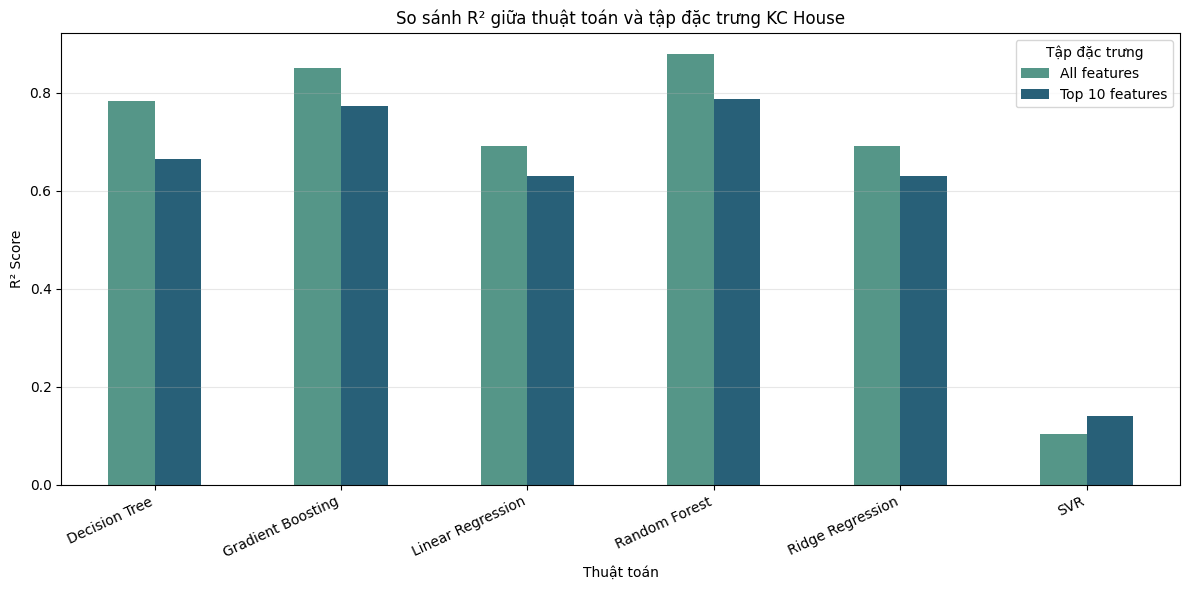

Mô hình tốt nhất: Random Forest | Tập: All features
MAE: 68225.86 USD
RMSE: 126058.5 USD
R²: 0.878


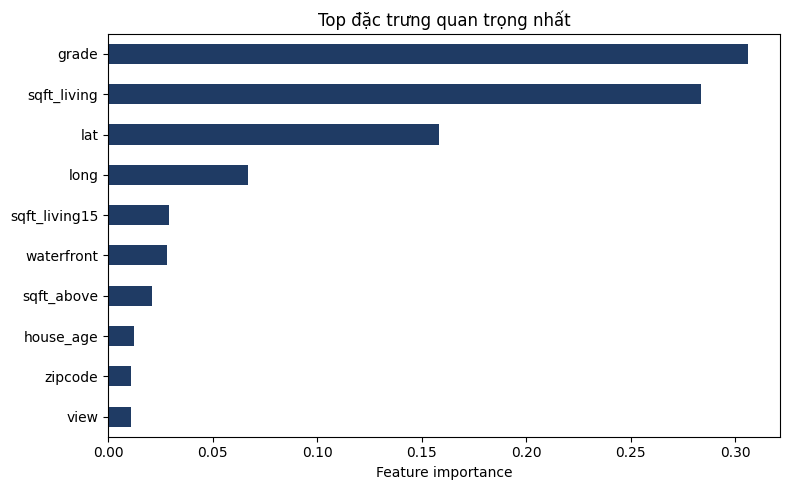

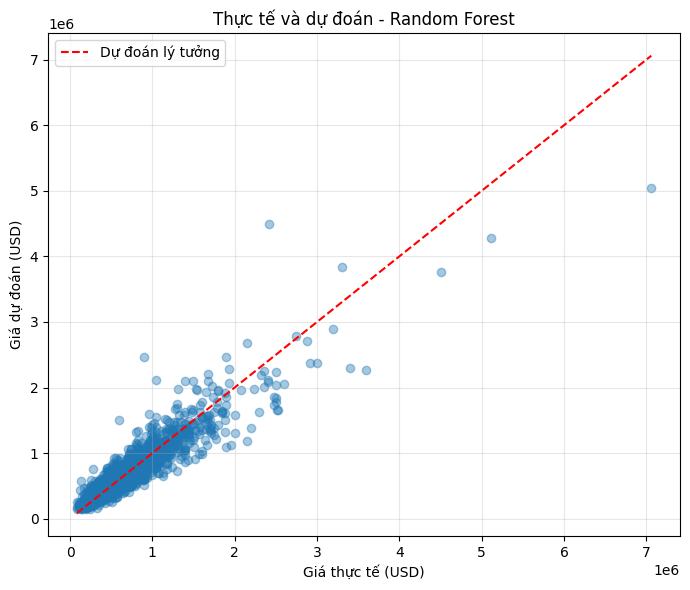

In [12]:
# Biểu đồ R² theo mô hình và bộ đặc trưng
pivot = results_b4_df.pivot(
    index="Thuật toán",
    columns="Tập đặc trưng",
    values="R²"
)
pivot.plot(kind="bar", figsize=(12, 6), color=["#559688", "#286078"])
plt.title("So sánh R² giữa thuật toán và tập đặc trưng KC House")
plt.xlabel("Thuật toán")
plt.ylabel("R² Score")
plt.xticks(rotation=25, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Lấy mô hình tốt nhất theo R²
best_house_row = results_b4_df.iloc[0]
best_house_key = (best_house_row["Tập đặc trưng"], best_house_row["Thuật toán"])
best_house_model = models_trained_b4[best_house_key]
best_house_pred = predictions_b4[best_house_key]
best_est = best_house_model.named_steps["model"]

print("Mô hình tốt nhất:", best_house_key[1], "| Tập:", best_house_key[0])
print("MAE:", round(best_house_row["MAE (USD)"], 2), "USD")
print("RMSE:", round(best_house_row["RMSE (USD)"], 2), "USD")
print("R²:", round(best_house_row["R²"], 4))

# Lấy đúng danh sách cột đã được tiền xử lý và đưa vào mô hình
best_cols = list(best_house_model.named_steps["preprocessor"].transformers_[0][2])

# Vẽ Feature Importance nếu mô hình hỗ trợ
if hasattr(best_est, "feature_importances_"):
    importances = pd.Series(
        best_est.feature_importances_,
        index=best_cols
    ).sort_values(ascending=False).head(10)

    importances.sort_values().plot(
        kind="barh",
        figsize=(8, 5),
        color="#1f3b64"
    )
    plt.title("Top đặc trưng quan trọng nhất")
    plt.xlabel("Feature importance")
    plt.tight_layout()
    plt.show()
else:
    print("Mô hình tốt nhất không có thuộc tính feature_importances_.")

# Biểu đồ giá trị thực tế và dự đoán
plt.figure(figsize=(7, 6))
plt.scatter(yh_test, best_house_pred, alpha=0.4)
low = min(yh_test.min(), best_house_pred.min())
high = max(yh_test.max(), best_house_pred.max())
plt.plot([low, high], [low, high], "r--", label="Dự đoán lý tưởng")
plt.title(f"Thực tế và dự đoán - {best_house_key[1]}")
plt.xlabel("Giá thực tế (USD)")
plt.ylabel("Giá dự đoán (USD)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## KẾT LUẬN CHUNG

- Bài 1 khảo sát phân phối, ngoại lệ, tương quan và scatter plot của `bmi`, `bp`, `s5`.

- Bài 2 so sánh Linear Regression với bốn nhóm đặc trưng qua MAE, RMSE, R².

- Bài 3 so sánh năm thuật toán hồi quy trên Diabetes.

- Bài 4 xây dựng pipeline cho KC House, so sánh sáu thuật toán với All features và Top 10.



Kết quả cụ thể được tính khi chạy notebook và có thể khác báo cáo nếu phiên bản thư viện hoặc cấu hình môi trường khác.
